# Лабораторная работа №5. Harris, собственные значения и локальные признаки

Условие — в [методичке](CSE5382_15_лабораторных_работ_математические_методы_in_CV.md), раздел «Лабораторная работа №5».

**Данные.** `data/blox.jpg` (256×256, кубики — много чётких углов) и `data/building.jpg`; оба из набора примеров OpenCV.

## 1. О чём эта работа

### Знакомый пример

Вы собираете пазл. Кусочек с ровным небом можно приложить куда угодно — он везде «подходит». Кусочек с прямой линией горизонта можно двигать вдоль линии — тоже неоднозначно. А кусочек с углом крыши встаёт на единственное место. Именно такие «однозначные» места нужны компьютеру, чтобы находить одну и ту же точку на разных фотографиях.

### Основная идея

Вырежем маленькое окно вокруг пикселя и чуть-чуть сдвинем его. Сравним, насколько изменилось содержимое.

- **Ровная область:** куда ни сдвинь — ничего не меняется.
- **Граница:** вдоль границы ничего не меняется, поперёк — меняется сильно.
- **Угол:** меняется при сдвиге в любую сторону.

Детектор Харриса не перебирает сдвиги, а выводит ответ из градиентов (их мы считали в лабораторной 4).

### Понятия

- **Structure tensor** (матрица вторых моментов) $M$ — матрица 2×2, собранная из градиентов внутри окна. Она отвечает на вопрос «насколько изменится окно при сдвиге $(u,v)$»: изменение $\approx [u\ v]\,M\,[u\ v]^T$. Такое выражение называется **квадратичной формой**.
- **Собственный вектор** матрицы — направление, которое матрица только растягивает, но не поворачивает: $Mv=\lambda v$. Число $\lambda$ — **собственное значение** (eigenvalue), коэффициент растяжения.
- Для $M$ собственные векторы — два перпендикулярных направления: вдоль одного окно меняется быстрее всего ($\lambda_1$), вдоль другого медленнее всего ($\lambda_2$).
  - оба $\lambda$ малы → ровная область (flat);
  - одно большое, другое малое → граница (edge);
  - оба большие → угол (corner).
- **Определитель** $\det M=ad-b^2$ и **след** $\mathrm{trace}\,M=a+d$ (для $M=\begin{bmatrix}a&b\\b&d\end{bmatrix}$). Они связаны с собственными значениями: $\det M=\lambda_1\lambda_2$, $\mathrm{trace}\,M=\lambda_1+\lambda_2$.

### Формулы

$$M=\sum_{\text{окно}}w\begin{bmatrix}I_x^2&I_xI_y\\I_xI_y&I_y^2\end{bmatrix}$$

$I_x,I_y$ — производные яркости в пикселях окна, $w$ — вес пикселя (1 для простого окна или гауссиана).

$$R=\det(M)-k\cdot\mathrm{trace}(M)^2=\lambda_1\lambda_2-k(\lambda_1+\lambda_2)^2$$

$k$ — эмпирическая константа (обычно 0.04–0.06). $R$ большое положительное — угол; отрицательное — граница; около нуля — ровная область. Формула позволяет не вычислять сами $\lambda$ (это потребовало бы квадратного корня в каждом пикселе).

In [1]:
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "image.cmap": "gray"})

IMAGE_PATH = "data/blox.jpg"
K_HARRIS = 0.04
BLOCK = 3                # окно суммирования
REL_THRESHOLD = 0.01     # порог R как доля от максимума
NMS_RADIUS = 3           # радиус non-maximum suppression, px
MATCH_RADIUS = 3         # радиус для repeatability, px
ANGLE = 30

## 2. Вопрос 1 — det, trace и R

> Для `M=[[120,30],[30,80]]`, k=0.04 вычислите det(M), trace(M) и R.

**Определитель** матрицы 2×2 — произведение главной диагонали минус произведение побочной: $\det M=120\cdot80-30\cdot30=9600-900=8700$.

**След** — сумма диагонали: $\mathrm{trace}\,M=120+80=200$.

**Отклик Харриса:** $R=8700-0.04\cdot200^2=8700-0.04\cdot40000=8700-1600=7100$.

**Смысл.** $R$ большое и положительное — это угол. Проверим через собственные значения: они равны $100\pm\sqrt{20^2+30^2}=100\pm36.06$, то есть $\lambda_1\approx136.06$, $\lambda_2\approx63.94$. Оба большие и одного порядка (отношение ≈ 2.1) — окно меняется при сдвиге в любом направлении.

In [2]:
M1 = np.array([[120.0, 30.0], [30.0, 80.0]])
det, tr = M1[0, 0] * M1[1, 1] - M1[0, 1] ** 2, M1[0, 0] + M1[1, 1]
R1 = det - K_HARRIS * tr ** 2
lam = np.linalg.eigvalsh(M1)
print("det =", det, " trace =", tr, " R =", R1)
print("eigenvalues:", lam, " произведение =", round(lam.prod(), 6), " сумма =", round(lam.sum(), 6))
print("R через λ:", round(lam.prod() - K_HARRIS * lam.sum() ** 2, 6))

det = 8700.0  trace = 200.0  R = 7100.0
eigenvalues: [ 63.9445 136.0555]  произведение = 8700.0  сумма = 200.0
R через λ: 7100.0


**Итог вопроса 1:** $\det=8700$, $\mathrm{trace}=200$, $R=7100$.

## 3. Вопрос 2 — собственные значения и инвариантность к повороту

> Для `M=[[5,2],[2,2]]` найдите eigenvalues и интерпретируйте структуру. Объясните, почему eigenvalues не меняются при M'=RMR^T для ортогонального R.

### Собственные значения

Ищем $\lambda$, при которых $Mv=\lambda v$ имеет ненулевое решение, то есть $\det(M-\lambda I)=0$:

$$\det\begin{bmatrix}5-\lambda&2\\2&2-\lambda\end{bmatrix}=(5-\lambda)(2-\lambda)-4=\lambda^2-7\lambda+6=0$$

Корни по теореме Виета (сумма 7, произведение 6): $\lambda_1=6$, $\lambda_2=1$. Проверка: сумма $=\mathrm{trace}=5+2=7$ ✓, произведение $=\det=10-4=6$ ✓.

### Интерпретация

$\lambda_1=6$ в шесть раз больше $\lambda_2=1$: вдоль одного направления окно меняется сильно, вдоль перпендикулярного — слабо. Это структура типа **границы**. Отклик Харриса: $R=6-0.04\cdot49=4.04$ — формально положительный, но в 3 раза меньше, чем был бы у «чистого угла» с тем же следом ($\lambda_1=\lambda_2=3.5$: $R=12.25-1.96=10.29$).

Собственный вектор для $\lambda_1=6$: $(5-6)v_x+2v_y=0\Rightarrow v=(2,1)/\sqrt5$ — направление самого быстрого изменения (поперёк границы), около 26.6° к оси $x$.

### Почему поворот не меняет собственные значения

Если повернуть изображение, градиенты повернутся: $g'=Rg$. Тогда $M'=\sum g'g'^T=R\big(\sum gg^T\big)R^T=RMR^T$.

Матрица $R$ **ортогональная**: $R^TR=I$, то есть $R^T=R^{-1}$. Пусть $Mv=\lambda v$. Возьмём $v'=Rv$:

$$M'v'=RMR^T\,Rv=RM\,(R^TR)\,v=RMv=R\lambda v=\lambda v'$$

То же число $\lambda$ осталось собственным значением, только собственный вектор повернулся вместе с картинкой. Раз $\lambda_1,\lambda_2$ не меняются, не меняются $\det$, $\mathrm{trace}$ и $R$ — детектор Харриса находит один и тот же угол независимо от того, как повёрнуто изображение.

In [3]:
M2 = np.array([[5.0, 2.0], [2.0, 2.0]])
vals, vecs = np.linalg.eigh(M2)
print("корни λ²−7λ+6:", np.roots([1, -7, 6]))
print("eigenvalues:", vals, " отношение:", vals[1] / vals[0])
print("собственный вектор для λ=6:", vecs[:, 1], " угол:", round(np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1])) % 180, 2), "°")
print("R Харриса:", vals.prod() - K_HARRIS * vals.sum() ** 2)

print("\nповорот системы координат:")
for deg in (0, 30, 45, 90, 137):
    t = np.radians(deg)
    Rm = np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])
    Mr = Rm @ M2 @ Rm.T
    print(f"  {deg:3d}°: M' = [[{Mr[0,0]:6.3f},{Mr[0,1]:6.3f}],[{Mr[1,0]:6.3f},{Mr[1,1]:6.3f}]]  eigenvalues = {np.linalg.eigvalsh(Mr)}")

корни λ²−7λ+6: [6. 1.]
eigenvalues: [1. 6.]  отношение: 6.0
собственный вектор для λ=6: [-0.8944 -0.4472]  угол: 26.57 °
R Харриса: 4.04

поворот системы координат:
    0°: M' = [[ 5.000, 2.000],[ 2.000, 2.000]]  eigenvalues = [1. 6.]
   30°: M' = [[ 2.518, 2.299],[ 2.299, 4.482]]  eigenvalues = [1. 6.]
   45°: M' = [[ 1.500, 1.500],[ 1.500, 5.500]]  eigenvalues = [1. 6.]
   90°: M' = [[ 2.000,-2.000],[-2.000, 5.000]]  eigenvalues = [1. 6.]
  137°: M' = [[ 5.600,-1.357],[-1.357, 1.400]]  eigenvalues = [1. 6.]


**Итог вопроса 2:** $\lambda_1=6$, $\lambda_2=1$ — структура типа границы; при повороте сама матрица меняется, а её собственные значения — нет.

## 4. Задание 3 — код и эксперимент

### Шаги 1–5. Собственный Harris response

Порядок: производные → три карты произведений → суммирование в окне (это и даёт элементы $M$ для каждого пикселя) → $\det$, $\mathrm{trace}$, $R$.

Суммирование в окне обязательно. Без него в одном пикселе $M=\begin{bmatrix}I_x^2&I_xI_y\\I_xI_y&I_y^2\end{bmatrix}$ и $\det M=I_x^2I_y^2-(I_xI_y)^2=0$ всегда: один градиент задаёт только одно направление. Угол — это место, где в окне встречаются градиенты **разных** направлений.

shape: (256, 256)


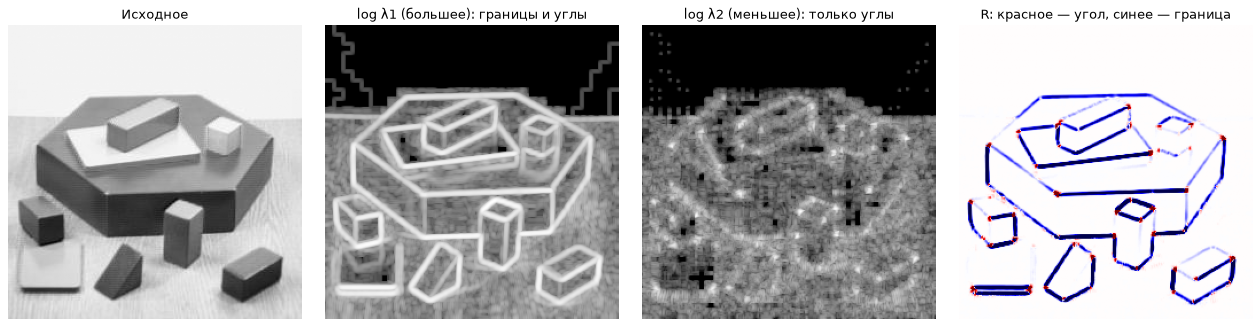

In [4]:
gray = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE).astype(np.float32)
print("shape:", gray.shape)

def harris_response(g, k=K_HARRIS, block=BLOCK):
    Ix = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
    Iy = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)
    Ix2, Iy2, Ixy = Ix * Ix, Iy * Iy, Ix * Iy
    # локальное суммирование: элементы M для каждого пикселя
    Sxx = cv2.boxFilter(Ix2, -1, (block, block), normalize=False)
    Syy = cv2.boxFilter(Iy2, -1, (block, block), normalize=False)
    Sxy = cv2.boxFilter(Ixy, -1, (block, block), normalize=False)
    det = Sxx * Syy - Sxy * Sxy
    trace = Sxx + Syy
    return det - k * trace ** 2, (Sxx, Syy, Sxy)

R, (Sxx, Syy, Sxy) = harris_response(gray)

# собственные значения M в каждом пикселе — только для иллюстрации
half_tr = (Sxx + Syy) / 2
root = np.sqrt(((Sxx - Syy) / 2) ** 2 + Sxy ** 2)
lam1, lam2 = half_tr + root, half_tr - root

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
ax[0].imshow(gray); ax[0].set_title("Исходное")
ax[1].imshow(np.log1p(lam1)); ax[1].set_title("log λ1 (большее): границы и углы")
ax[2].imshow(np.log1p(np.maximum(lam2, 0))); ax[2].set_title("log λ2 (меньшее): только углы")
v = np.abs(R).max() * 0.05
ax[3].imshow(R, cmap="seismic", vmin=-v, vmax=v); ax[3].set_title("R: красное — угол, синее — граница")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

Карта $\lambda_1$ похожа на карту границ, карта $\lambda_2$ светится только в углах — там, где есть второе направление изменения. На карте $R$ границы синие ($R<0$), углы красные ($R>0$).

### Сравнение с `cv2.cornerHarris`

OpenCV внутри нормирует производные: делит результат Собеля на $2^{ksize-1}\cdot blockSize=4\cdot3=12$. $R$ состоит из произведений четырёх производных, поэтому отклик OpenCV меньше нашего ровно в $12^4=20736$ раз. На положение углов масштаб не влияет.

In [5]:
R_cv = cv2.cornerHarris(gray, blockSize=BLOCK, ksize=3, k=K_HARRIS)
scale = 12.0 ** 4
rel = np.abs(R / scale - R_cv).max() / np.abs(R_cv).max()
print("корреляция R и R_cv:", np.corrcoef(R.ravel(), R_cv.ravel())[0, 1])
print(f"max |R/12⁴ − R_cv| относительно max|R_cv|: {rel:.2e}")

корреляция R и R_cv: 0.9999999999999698
max |R/12⁴ − R_cv| относительно max|R_cv|: 8.74e-07


### Шаг 6. Порог и non-maximum suppression

Вокруг настоящего угла $R$ велико в целом пятне. Оставляем по одной точке на пятно: пиксель считается углом, если его $R$ выше порога и он — максимум в своей окрестности. Максимум по окрестности считаем дилатацией (лабораторная 4): она заменяет каждый пиксель на наибольшее значение в окне.

In [6]:
def corners_from_response(Rmap, rel_thr=REL_THRESHOLD, radius=NMS_RADIUS, border=4):
    size = 2 * radius + 1
    local_max = cv2.dilate(Rmap, np.ones((size, size), np.uint8))
    keep = (Rmap == local_max) & (Rmap > rel_thr * Rmap.max())
    keep[:border] = keep[-border:] = False
    keep[:, :border] = keep[:, -border:] = False
    ys, xs = np.nonzero(keep)
    order = np.argsort(-Rmap[ys, xs])
    return np.column_stack([xs, ys])[order].astype(np.float32)      # (x, y), сильные первыми

pts_mine = corners_from_response(R)
pts_cv = corners_from_response(R_cv)
print("углов (свой R):", len(pts_mine), "  углов (cv2.cornerHarris + тот же отбор):", len(pts_cv))

углов (свой R): 55   углов (cv2.cornerHarris + тот же отбор): 55


### Шаг 7. Сравнение координат с OpenCV

Для каждого своего угла ищем ближайший угол из другого набора; считаем долю тех, у кого сосед ближе `MATCH_RADIUS`. Сравниваем с двумя наборами: `cv2.cornerHarris` с тем же отбором и `cv2.goodFeaturesToTrack` (детектор Shi–Tomasi: вместо $R$ он использует напрямую $\min(\lambda_1,\lambda_2)$).

свой Harris ↔ cv2.cornerHarris  : 1.0  точное совпадение наборов: True
свой Harris ↔ goodFeaturesToTrack: 0.873 (Shi–Tomasi нашёл 55 точек)


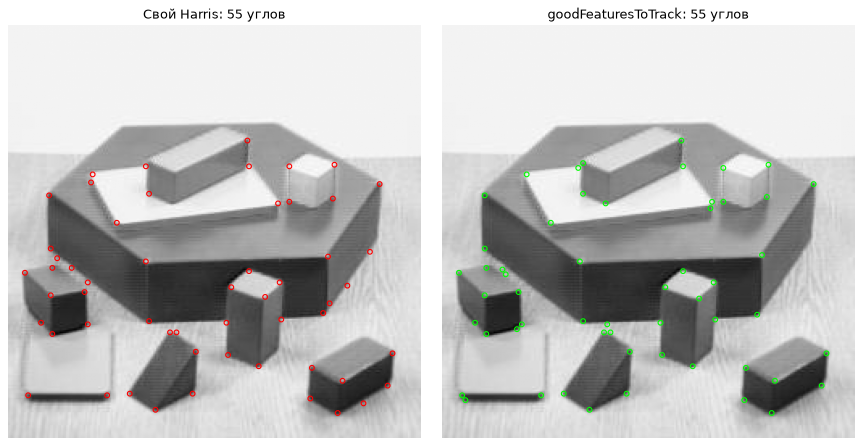

In [7]:
def match_fraction(a, b, radius=MATCH_RADIUS):
    """Доля точек из a, у которых есть точка из b ближе radius."""
    if len(a) == 0 or len(b) == 0:
        return 0.0
    d = np.linalg.norm(a[:, None, :] - b[None, :, :], axis=2)
    return float((d.min(axis=1) <= radius).mean())

pts_gftt = cv2.goodFeaturesToTrack(gray, maxCorners=len(pts_mine), qualityLevel=0.01, minDistance=NMS_RADIUS, blockSize=BLOCK).reshape(-1, 2)
print("свой Harris ↔ cv2.cornerHarris  :", match_fraction(pts_mine, pts_cv), " точное совпадение наборов:", bool(len(pts_mine) == len(pts_cv) and np.array_equal(np.sort(pts_mine, axis=0), np.sort(pts_cv, axis=0))))
print("свой Harris ↔ goodFeaturesToTrack:", round(match_fraction(pts_mine, pts_gftt), 3), f"(Shi–Tomasi нашёл {len(pts_gftt)} точек)")

fig, ax = plt.subplots(1, 2, figsize=(11, 5.5))
for a, (pts, title, col) in zip(ax, [(pts_mine, f"Свой Harris: {len(pts_mine)} углов", "red"), (pts_gftt, f"goodFeaturesToTrack: {len(pts_gftt)} углов", "lime")]):
    a.imshow(gray); a.scatter(pts[:, 0], pts[:, 1], s=18, facecolors="none", edgecolors=col); a.set_title(title); a.axis("off")
plt.tight_layout(); plt.show()

### Шаги 8–9. Поворот на 30° и repeatability

**Repeatability** (повторяемость) — доля точек, найденных на исходном изображении, которые детектор снова находит на преобразованном, в том же месте сцены. Мы знаем точное преобразование, поэтому можем пересчитать координаты исходных углов и проверить, есть ли рядом найденный угол.

Чтобы после поворота углы картинки не обрезались, холст увеличен. Матрица поворота $A$ размера 2×3 переводит точку $(x,y)$ в $A\,[x,y,1]^T$.

Harris (свой): 55 углов на исходном, 49 на повёрнутом, repeatability при r=3px = 0.873


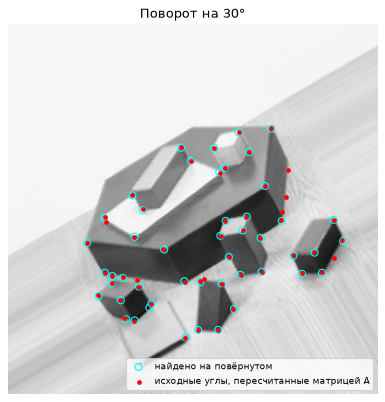

In [8]:
def rotate_with_canvas(img, angle):
    h, w = img.shape[:2]
    A = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    cos, sin = abs(A[0, 0]), abs(A[0, 1])
    nw, nh = int(h * sin + w * cos), int(h * cos + w * sin)
    A[0, 2] += nw / 2 - w / 2
    A[1, 2] += nh / 2 - h / 2
    return cv2.warpAffine(img, A, (nw, nh), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE), A

def transform_points(pts, A):
    return (A @ np.c_[pts, np.ones(len(pts))].T).T.astype(np.float32)

gray_rot, A = rotate_with_canvas(gray, ANGLE)

def detect_harris(g):
    return corners_from_response(harris_response(g)[0])

def detect_shi_tomasi(g):
    return cv2.goodFeaturesToTrack(g, maxCorners=500, qualityLevel=0.01, minDistance=NMS_RADIUS, blockSize=BLOCK).reshape(-1, 2)

sift, orb = cv2.SIFT_create(), cv2.ORB_create(nfeatures=500)
def detect_sift(g):
    return np.array([k.pt for k in sift.detect(g.astype(np.uint8), None)], np.float32).reshape(-1, 2)
def detect_orb(g):
    return np.array([k.pt for k in orb.detect(g.astype(np.uint8), None)], np.float32).reshape(-1, 2)

def repeatability(detect, img, img_t, A, radius=MATCH_RADIUS):
    p0, p1 = detect(img), detect(img_t)
    return match_fraction(transform_points(p0, A), p1, radius), len(p0), len(p1)

def avg_time(detect, img, runs=20):
    ts = []
    for _ in range(runs):
        t0 = time.perf_counter(); detect(img); ts.append(time.perf_counter() - t0)
    return 1000 * np.mean(ts)

rep, n0, n1 = repeatability(detect_harris, gray, gray_rot, A)
print(f"Harris (свой): {n0} углов на исходном, {n1} на повёрнутом, repeatability при r={MATCH_RADIUS}px = {rep:.3f}")

p0t, p1 = transform_points(pts_mine, A), detect_harris(gray_rot)
plt.figure(figsize=(6, 6))
plt.imshow(gray_rot)
plt.scatter(p1[:, 0], p1[:, 1], s=40, facecolors="none", edgecolors="cyan", label="найдено на повёрнутом")
plt.scatter(p0t[:, 0], p0t[:, 1], s=10, c="red", label="исходные углы, пересчитанные матрицей A")
plt.legend(loc="lower right", fontsize=8); plt.title(f"Поворот на {ANGLE}°"); plt.axis("off"); plt.show()

### Шаг 10. Сравнение с Shi–Tomasi, SIFT и ORB

SIFT и ORB — детекторы, которые ищут точки сразу на нескольких масштабах изображения и для каждой запоминают масштаб и ориентацию. Здесь сравниваем только детектирование (координаты), без дескрипторов.

In [9]:
detectors = {"Harris (свой)": detect_harris, "Shi–Tomasi": detect_shi_tomasi, "SIFT": detect_sift, "ORB": detect_orb}
print(f"{'Метод':16}{'Keypoints':>10}{'Repeatability':>15}{'Среднее время, ms':>19}")
table = {}
for name, det_fn in detectors.items():
    rep, n0, _ = repeatability(det_fn, gray, gray_rot, A)
    t = avg_time(det_fn, gray)
    table[name] = (n0, rep, t)
    print(f"{name:16}{n0:10d}{rep:15.3f}{t:19.2f}")

Метод            Keypoints  Repeatability  Среднее время, ms
Harris (свой)           55          0.873               1.49
Shi–Tomasi             332          0.789               0.54


SIFT                   187          0.690               8.86
ORB                    290          0.945               0.73


## 5. Неудачные случаи: масштаб и шум

Харрис инвариантен к повороту (вопрос 2), но не к масштабу: окно суммирования имеет фиксированный размер 3×3. Проверим на увеличении и уменьшении в 2 и 4 раза. Второй опыт — гауссов шум σ=20: сцена та же, преобразование тождественное.

Допуск при сопоставлении всегда равен 3 px в координатах исходного изображения (на уменьшенной вдвое картинке это 1.5 px), иначе сравнение масштабов было бы нечестным.

In [10]:
SCALES = (4.0, 2.0, 0.5, 0.25)
rng = np.random.default_rng(0)
noisy = np.clip(gray + rng.normal(0, 20, gray.shape), 0, 255).astype(np.float32)
I2 = np.array([[1, 0, 0], [0, 1, 0]], dtype=np.float64)

print("repeatability; допуск всегда 3 px в координатах ИСХОДНОГО изображения")
print(f"{'Метод':16}{'поворот 30°':>13}" + "".join(f"{f'масштаб ×{s:g}':>15}" for s in SCALES) + f"{'шум σ=20':>12}{'точек при шуме':>16}")
for name, det_fn in detectors.items():
    row = [table[name][1]]
    for s in SCALES:
        g_s = cv2.resize(gray, None, fx=s, fy=s, interpolation=cv2.INTER_LINEAR if s > 1 else cv2.INTER_AREA)
        S = np.array([[s, 0, 0], [0, s, 0]], dtype=np.float64)
        row.append(repeatability(det_fn, gray, g_s, S, radius=MATCH_RADIUS * s)[0])
    rep_n, _, n_noisy = repeatability(det_fn, gray, noisy, I2)
    print(f"{name:16}{row[0]:13.3f}" + "".join(f"{r:15.3f}" for r in row[1:]) + f"{rep_n:12.3f}{n_noisy:16d}")

repeatability; допуск всегда 3 px в координатах ИСХОДНОГО изображения
Метод             поворот 30°     масштаб ×4     масштаб ×2   масштаб ×0.5  масштаб ×0.25    шум σ=20  точек при шуме
Harris (свой)           0.873          0.818          0.873          0.727          0.200       0.818             482
Shi–Tomasi              0.789          0.431          0.617          0.280          0.099       0.524             500
SIFT                    0.690          0.636          0.679          0.439          0.219       0.513             354


ORB                     0.945          0.590          0.855          0.645          0.000       0.931             401


**Масштаб.** При увеличении повторяемость Харриса почти не страдает (0.82–0.87), а при уменьшении падает: 0.73 при ×0.5 и всего 0.20 при ×0.25. На кадре 64×64 кубики занимают несколько пикселей, соседние углы сливаются в окне 3×3, и точного положения уже не восстановить. Фиксированное окно означает фиксированный физический масштаб детектора. Остальные детекторы при ×0.25 тоже не справляются (ORB не нашёл ни одной точки) — картинка 64×64 слишком мала и для пирамиды масштабов.

**Шум.** Здесь ошибка другого рода. Повторяемость формально высокая (0.82), но число найденных «углов» выросло с 55 до 482: около 430 точек — ложные. Шум даёт в окне градиенты случайных направлений, а это ровно тот признак, по которому Харрис узнаёт угол: оба собственных значения ненулевые. Порог задан относительно максимума $R$ и ложные точки не отсекает. Высокая повторяемость при этом отчасти обманчива: когда точек на втором кадре в девять раз больше, шанс случайного попадания в радиус 3 px тоже выше.

Третье ограничение видно на шаге 9: даже при чистом повороте повторяемость 0.87, а не 1. Поворот требует интерполяции (она слегка размывает картинку), а углы, оказавшиеся у порога, попадают то по одну, то по другую его сторону.

## 6. Вывод

Цифры — из таблиц выше для `data/blox.jpg`.

- **Flat / edge / corner.** Тип области определяется соотношением собственных значений $M$: оба малы — ровная, одно большое — граница, оба большие — угол. Это хорошо видно на картах: $\lambda_1$ высвечивает все границы, $\lambda_2$ — только углы. $R=\lambda_1\lambda_2-k(\lambda_1+\lambda_2)^2$ кодирует то же самое одним числом: произведение велико, только если велики оба сомножителя; вычитаемое штрафует случай «одно $\lambda$ много больше другого».
- **Проверка реализации.** Собственный $R$ совпадает с `cv2.cornerHarris` с точностью до постоянного множителя $12^4$ (относительная разность ~1e-6, корреляция 1.0); наборы из 55 углов идентичны. С Shi–Tomasi (`goodFeaturesToTrack`, те же 55 сильнейших точек) совпадает 87 % углов — критерии разные, но близкие.
- **Поворот на 30°.** Повторяемость собственного Харриса 0.87 при радиусе 3 px (55 углов на исходном, 49 на повёрнутом): большинство углов найдено снова, как и предсказывает инвариантность собственных значений; потери — из-за интерполяции и порога.
- **Масштаб.** При уменьшении вчетверо повторяемость падает до 0.20 — инвариантности к масштабу у метода нет.
- **Шум.** При σ=20 Харрис находит 482 точки вместо 55 — почти все ложные.
- **Количество не равно качеству.** На чистом кадре детекторы нашли 55 (Harris), 332 (Shi–Tomasi), 187 (SIFT) и 290 (ORB) точек, а повторяемость при повороте — 0.87, 0.79, 0.69 и 0.95 соответственно: связи с количеством нет. Важны повторяемость, точность локализации и равномерность покрытия. Сравнивать repeatability у детекторов с разным числом точек нужно осторожно: чем больше точек на втором кадре, тем выше шанс случайного совпадения в радиусе 3 px.
- **Время.** Shi–Tomasi и ORB — меньше 1 ms на кадр 256×256, собственный Харрис ≈ 1.4 ms, SIFT ≈ 8 ms: он строит пирамиду гауссиан (миллисекунды зависят от компьютера).

## 7. Вопросы на защиту

**1. Что физически означают две eigenvalues structure tensor?**
Это изменение содержимого окна (сумма квадратов разностей) при единичном сдвиге вдоль двух перпендикулярных главных направлений: $\lambda_1$ — вдоль направления самого быстрого изменения, $\lambda_2$ — самого медленного. Иначе: $\lambda_1,\lambda_2$ — «энергия» градиентов в окне вдоль двух главных осей. Если построить эллипс $[u\ v]M[u\ v]^T=1$, его полуоси равны $1/\sqrt{\lambda}$.

**2. Почему Harris score можно выразить через det и trace без явного вычисления eigenvalues?**
Потому что для любой матрицы 2×2 $\det M=\lambda_1\lambda_2$ и $\mathrm{trace}\,M=\lambda_1+\lambda_2$ (коэффициенты характеристического многочлена, теорема Виета). $R$ зависит от $\lambda$ только через произведение и сумму, поэтому считается из элементов матрицы: $R=(S_{xx}S_{yy}-S_{xy}^2)-k(S_{xx}+S_{yy})^2$ — несколько умножений на пиксель без квадратного корня.

**3. Код вычисления R; где формируется матрица M для каждого пикселя.**
В `harris_response`: `Ix2, Iy2, Ixy` — попиксельные произведения производных. Три вызова `cv2.boxFilter(..., normalize=False)` суммируют их по окну 3×3 — после этого в пикселе $(i,j)$ числа `Sxx[i,j], Sxy[i,j], Syy[i,j]` и есть три разных элемента симметричной матрицы $M$ для этого пикселя. Матрица нигде не хранится как массив 2×2: `det = Sxx*Syy - Sxy*Sxy` и `trace = Sxx + Syy` считаются сразу для всех пикселей, затем `R = det - k*trace**2`.